# **TUGAS 1 Breast Cancer Classification Using Machine Learning**

**Implementasi Machine Learning Menggunakan Python dan Google Colab**

Pada contoh ini, kita akan membangun model Machine Learning untuk melakukan klasifikasi kanker payudara ogistic Regression dan Random Forest Classifier

Dataset yang digunakan adalah Breast Cancer Wisconsin Dataset yang tersedia pada Scikit-learn. Dataset ini memiliki 569 sampel dengan 30 fitur numerik yang menggambarkan karakteristik sel tumor.

Model akan dilatih untuk mengklasifikasikan tumor ke dalam dua kategori:

*   Malignant (0): Tumor ganas.
*   Benign (1): Tumor jinak.

Proses implementasi dilakukan menggunakan Google Colab sehingga mahasiswa tidak perlu melakukan instalasi Python dan library secara manual pada komputer masing-masing.

# **Step 1: Import Libraries**

Tahap pertama adalah mengimpor library Python yang diperlukan untuk proses pengolahan data, visualisasi, pembangunan model Machine Learning, dan evaluasi performa model.

In [16]:
# Library untuk pengolahan data numerik
import numpy as np
import pandas as pd

# Library untuk visualisasi data
import matplotlib.pyplot as plt
import seaborn as sns

# Mengambil dataset Breast Cancer dari Scikit-learn
from sklearn.datasets import load_breast_cancer

# Library untuk membagi dataset dan normalisasi data
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Library untuk membangun pipeline dan model klasifikasi
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Library untuk evaluasi performa model
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score
)

print("Semua library berhasil dimasukkan")

Semua library berhasil dimasukkan


**Penjelasan:**
- *numpy* dan pandas digunakan untuk pengolahan data.
- ***matplotlib dan seaborn*** digunakan untuk visualisasi.
- load_breast_cancer() digunakan untuk mengambil dataset.
- train_test_split() digunakan untuk membagi dataset.
- StandardScaler() digunakan untuk standardisasi fitur.
- LogisticRegression() digunakan untuk membangun model Logistic Regression.
- RandomForestClassifier() digunakan untuk membangun model Random Forest.
- Library sklearn.metrics digunakan untuk mengevaluasi performa kedua algoritma.

# **Step 2: Load Dataset**

Pada tahap ini, kita akan memuat Breast Cancer Wisconsin Dataset menggunakan fungsi load_breast_cancer() dari Scikit-learn.

Dataset kemudian dikonversi menjadi DataFrame menggunakan Pandas agar lebih mudah dianalisis.

In [18]:
# Memuat Breast Cancer Wisconsin Dataset
data = load_breast_cancer()

# Mengambil fitur dan mengubahnya menjadi DataFrame
X = pd.DataFrame(
    data.data,
    columns=data.feature_names
)

# Mengambil label atau target kelas
y = data.target

# Menampilkan dimensi dataset
print("Dataset Shape:", X.shape)

# Menampilkan lima sampel pertama
print("\nFirst 5 Samples:")
print(X.head())

# Menampilkan nama kelas target
print("\nTarget Classes:")
print(data.target_names)

Dataset Shape: (569, 30)

First 5 Samples:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  wor

Penjelasan:

*   data.data berisi data numerik yang digunakan sebagai fitur masukan.
*   data.feature_names berisi nama dari masing-masing fitur.
*   data.target berisi label atau kategori tumor.
*   X merupakan variabel yang menyimpan fitur karakteristik sel tumor.
*   y merupakan variabel yang menyimpan target klasifikasi tumor.
*   kelas 0 adalah Malignant (tumor ganas).
*   Kelas 1 adalah Benign (tumor jinak).

# **Step 3: Exploratory Data Analysis (EDA)**

Exploratory Data Analysis (EDA) merupakan proses eksplorasi dataset untuk memahami karakteristik data sebelum digunakan dalam proses pelatihan model Machine Learning.

Pada tahap ini, kita akan memeriksa:

*   Jumlah sampel pada setiap kelas.
*   Distribusi data.
*   Nilai yang hilang (missing values).
*   Karakteristik fitur yang digunakan.

In [19]:
# Menampilkan informasi umum dataset
print("Dataset Information:")
print(X.info())

# Memeriksa jumlah missing values
print("\nMissing Values:")
print(X.isnull().sum().sum())

# Menampilkan statistik deskriptif
print("\nStatistical Description:")
print(X.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoot

Penjelasan:

*   info() menampilkan informasi tipe data dan jumlah data pada setiap fitur.
*   isnull().sum().sum() menghitung total nilai yang hilang.
*   describe() menampilkan statistik deskriptif seperti mean, standar deviasi, minimum, dan maksimum.

**Check Class Distribution**

Selanjutnya, kita akan melihat distribusi jumlah sampel untuk masing-masing kelas tumor.

Class Distribution:
0    212
1    357
Name: count, dtype: int64


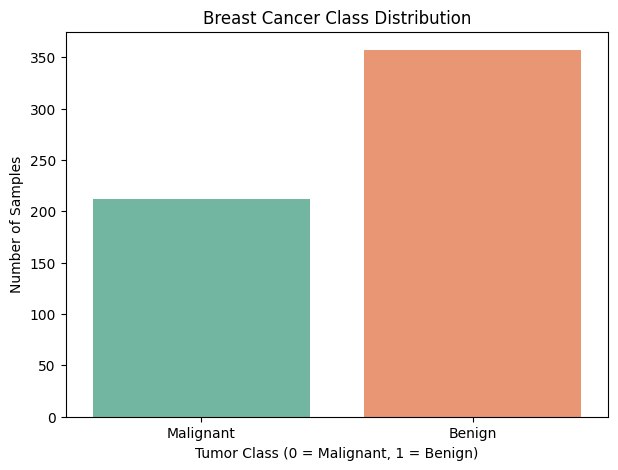

In [20]:
# Menghitung jumlah sampel pada setiap kelas
class_counts = pd.Series(y).value_counts().sort_index()

# Menampilkan jumlah sampel
print("Class Distribution:")
print(class_counts)

# Visualisasi distribusi kelas
plt.figure(figsize=(7, 5))

sns.countplot(
    x=y,
    hue=y,
    palette="Set2",
    legend=False
)

plt.title("Breast Cancer Class Distribution")
plt.xlabel("Tumor Class (0 = Malignant, 1 = Benign)")
plt.ylabel("Number of Samples")
plt.xticks([0, 1], ["Malignant", "Benign"])

plt.show()

Penjelasan:

Visualisasi ini digunakan untuk mengetahui jumlah sampel pada masing-masing kategori.

Informasi distribusi kelas penting karena ketidakseimbangan jumlah sampel dapat memengaruhi proses pelatihan dan evaluasi model.

# **Step 4: Dataset Splitting**

Sebelum membangun model Machine Learning, dataset perlu dibagi menjadi dua bagian:

*   Training Data: Data yang digunakan untuk melatih model.
*   Testing Data: Data yang digunakan untuk menguji kemampuan model terhadap data yang tidak digunakan selama pelatihan.

Pada contoh ini, kita menggunakan pembagian:

*   70% Training Data.
*   30% Testing Data.

In [21]:
# Membagi dataset menjadi training dan testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

# Menampilkan jumlah data
print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

print("\nTraining Features:", X_train.shape)
print("Testing Features:", X_test.shape)

Training Samples: 398
Testing Samples: 171

Training Features: (398, 30)
Testing Features: (171, 30)


Penjelasan parameter:
* test_size=0.3: Sebanyak 30% data digunakan untuk pengujian.
* random_state=42: Menjaga konsistensi pembagian dataset.
* stratify=y: Mempertahankan proporsi kelas pada data training dan testing.

# **Step 5: Data Normalization (Feature Scaling) dan Model Building**

Fitur dalam dataset memiliki rentang nilai yang berbeda.

Perbedaan skala tersebut dapat memengaruhi proses optimasi algoritma Machine Learning seperti Logistic Regression.

Oleh karena itu, kita menggunakan StandardScaler untuk melakukan standardisasi fitur pada Logistic Regression.

Standardisasi dilakukan menggunakan persamaan:
\[z = \frac{x-\mu}{\sigma}\]


Keterangan:
- \(x\) = Nilai fitur awal.
- \(\mu\) = Rata-rata fitur.
- \(\sigma\) = Standar deviasi fitur.
- \(z\) = Nilai fitur setelah standardisasi.
Dalam implementasi ini, StandardScaler dimasukkan ke dalam Pipeline agar proses standardisasi dilakukan secara otomatis.

**A. Logistic Regression**


In [22]:
# Membuat pipeline yang menggabungkan standardisasi
# dan Logistic Regression
model_lr = make_pipeline(
    StandardScaler(),

    LogisticRegression(
        max_iter=1000,
        random_state=42
    )
)

# Melatih model menggunakan data training
model_lr.fit(X_train, y_train)

print("Logistic Regression Training Completed!")

Logistic Regression Training Completed!


Penjelasan:

- StandardScaler() digunakan untuk menyamakan skala fitur.
- LogisticRegression() digunakan untuk membangun model klasifikasi.
- max_iter=1000 menentukan jumlah maksimum iterasi.
- fit() digunakan untuk melatih model menggunakan data training.

**B. Random Forest Classifier**
Random Forest merupakan algoritma klasifikasi berbasis kumpulan beberapa Decision Tree yang menggabungkan hasil prediksi untuk menentukan kelas akhir.

In [32]:
# Membangun model Random Forest Classifier
model_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Melatih model menggunakan data training
model_rf.fit(X_train, y_train)

print("Random Forest Training Completed!")

Random Forest Training Completed!


Penjelasan:
- RandomForestClassifier() digunakan untuk membangun model klasifikasi.
- n_estimators=100 berarti model menggunakan 100 Decision Tree.
- random_state=42 menjaga konsistensi hasil eksperimen.
- fit() digunakan untuk melatih model menggunakan data training.

# **Step 6: Model Prediction**

Setelah model berhasil dilatih, langkah berikutnya adalah melakukan prediksi menggunakan data testing.

Model akan menghasilkan prediksi kategori tumor berdasarkan karakteristik fitur yang diberikan.

In [33]:
# Melakukan prediksi menggunakan Logistic Regression
y_pred_lr = model_lr.predict(X_test)

# Melakukan prediksi menggunakan Random Forest
y_pred_rf = model_rf.predict(X_test)

# Menampilkan hasil prediksi Logistic Regression
print("Logistic Regression Predicted Classes:")
print(y_pred_lr)

# Menampilkan hasil prediksi Random Forest
print("\nRandom Forest Predicted Classes:")
print(y_pred_rf)

# Menampilkan label sebenarnya
print("\nActual Classes:")
print(y_test)

Logistic Regression Predicted Classes:
[0 1 1 0 0 0 1 0 1 0 1 1 0 1 1 0 0 1 1 1 1 1 1 0 0 1 1 1 0 0 1 0 1 1 0 1 1
 1 1 1 1 0 1 1 1 1 1 1 1 0 1 1 0 0 1 1 0 1 1 1 0 0 0 1 1 1 1 0 1 1 0 0 0 0
 1 1 1 1 0 1 1 1 0 1 0 1 1 0 0 0 0 1 1 1 1 1 0 1 0 1 1 1 1 0 1 1 1 1 0 1 0
 1 0 1 1 0 0 1 1 0 1 1 0 1 0 1 1 0 1 1 1 1 0 1 0 1 0 1 0 1 1 1 0 0 0 0 0 1
 0 1 1 1 0 1 0 1 1 0 1 1 0 0 1 1 0 1 1 1 1 0 1]

Random Forest Predicted Classes:
[0 1 1 0 1 0 1 0 1 0 1 1 0 1 1 0 0 0 1 1 1 1 1 0 0 1 1 1 0 0 1 0 1 1 0 1 0
 1 1 1 1 0 1 1 1 1 1 1 1 0 1 1 0 0 1 1 0 1 1 1 0 0 0 1 1 1 1 0 1 1 0 0 0 0
 1 1 0 1 0 1 1 1 0 1 0 1 1 0 0 0 0 1 1 1 1 1 0 1 1 1 1 1 1 0 1 1 1 1 0 1 0
 1 0 1 1 0 1 1 1 0 1 1 0 1 1 1 1 0 1 1 1 1 0 1 0 1 0 1 1 1 1 1 0 0 0 0 0 1
 1 1 1 1 0 1 0 1 1 0 1 1 0 0 0 1 0 1 1 1 0 0 1]

Actual Classes:
[0 1 1 0 0 0 1 0 1 0 1 1 0 0 1 0 0 1 1 1 1 1 1 0 0 1 1 1 0 0 1 0 1 1 0 1 1
 1 1 1 1 0 1 1 1 1 1 1 1 0 1 1 0 0 1 1 0 1 1 1 0 0 0 1 1 1 1 0 1 1 0 0 0 0
 1 1 1 1 0 1 1 1 0 1 0 1 1 0 0 0 0 1 1 1 1 1 0 1 0 1 1 1 1 0 1 1

Penjelasan:

- Penjelasan:
- y_pred_lr menyimpan hasil prediksi Logistic Regression.
- y_pred_rf menyimpan hasil prediksi Random Forest.
- y_test menyimpan kelas sebenarnya dari data testing.

# **Step 7: Model Evaluation**

Pada tahap ini, mengevaluasi performa kedua algoritma menggunakan lima metrik utama:
1. Accuracy
2. Precision
3. Recall
4. F1-Score
5. ROC-AUC
Untuk membandingkan kedua model secara keseluruhan, kita menggunakan rata-rata macro (average='macro'). Dengan demikian, kedua kelas mendapatkan bobot yang sama dalam perhitungan metrik.

***A. Classification Report***
Untuk melihat performa masing-masing kelas secara lebih detail, kita juga menggunakan classification report.

**Accuracy**

Accuracy menunjukkan persentase jumlah prediksi yang benar dibandingkan dengan keseluruhan jumlah data pengujian.

$$
Accuracy = \frac{TP+TN}{TP+TN+FP+FN}
$$

Keterangan:

- TP = True Positive.
- TN = True Negative.
- FP = False Positive.
- FN = False Negative.

In [25]:
# Menghitung akurasi Logistic Regression
accuracy_lr = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Accuracy:", accuracy_lr)
print("Logistic Regression Accuracy (%):", accuracy_lr * 100)

# Menghitung akurasi Random Forest
accuracy_rf = accuracy_score(y_test, y_pred_rf)

print("\nRandom Forest Accuracy:", accuracy_rf)
print("Random Forest Accuracy (%):", accuracy_rf * 100)

Logistic Regression Accuracy: 0.9883040935672515
Logistic Regression Accuracy (%): 98.83040935672514

Random Forest Accuracy: 0.935672514619883
Random Forest Accuracy (%): 93.56725146198829


**Penjelasan:**

- Accuracy: Mengukur persentase keseluruhan prediksi yang benar.
- Precision: Mengukur ketepatan hasil prediksi suatu kelas.
- Recall: Mengukur kemampuan model menemukan seluruh data dari suatu kelas.
- F1-Score: Menggabungkan precision dan recall dalam satu nilai.

**B. Classification report**
Classification Report digunakan untuk menampilkan nilai Precision, Recall, dan F1-Score dari masing-masing kelas secara lebih detail.

In [26]:
# Classification Report Logistic Regression
print("Classification Report - Logistic Regression:")

print(
    classification_report(
        y_test,
        y_pred_lr,
        target_names=data.target_names
    )
)

# Classification Report Random Forest
print("\nClassification Report - Random Forest:")

print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=data.target_names
    )
)

Classification Report - Logistic Regression:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        64
      benign       0.99      0.99      0.99       107

    accuracy                           0.99       171
   macro avg       0.99      0.99      0.99       171
weighted avg       0.99      0.99      0.99       171


Classification Report - Random Forest:
              precision    recall  f1-score   support

   malignant       0.92      0.91      0.91        64
      benign       0.94      0.95      0.95       107

    accuracy                           0.94       171
   macro avg       0.93      0.93      0.93       171
weighted avg       0.94      0.94      0.94       171



**Penjelasan:**
- Precision mengukur ketepatan prediksi pada suatu kelas.
- Recall mengukur kemampuan model menemukan seluruh sampel dari suatu kelas.
- F1-Score merupakan harmonic mean antara precision dan recall.
Classification Report menampilkan hasil untuk kelas Malignant, Benign, serta rata-rata keseluruhan.

**C. ROC-AUC**

ROC-AUC digunakan untuk mengukur kemampuan model dalam membedakan dua kelas berdasarkan berbagai nilai threshold.

Pada notebook contoh, probabilitas yang digunakan adalah probabilitas kelas 1 (Benign). Kita pertahankan cara tersebut agar sesuai dengan rujukan.

In [27]:
# Mengambil probabilitas prediksi kelas 1 (Benign)
y_probability_lr = model_lr.predict_proba(X_test)[:, 1]

y_probability_rf = model_rf.predict_proba(X_test)[:, 1]

# Menghitung nilai ROC-AUC Logistic Regression
auc_lr = roc_auc_score(y_test, y_probability_lr)

# Menghitung nilai ROC-AUC Random Forest
auc_rf = roc_auc_score(y_test, y_probability_rf)

print("Logistic Regression ROC-AUC:", auc_lr)

print("Random Forest ROC-AUC:", auc_rf)

Logistic Regression ROC-AUC: 0.9981016355140186
Random Forest ROC-AUC: 0.991311331775701


**D. Perbandingan Hasil Evaluasi Kedua Algoritma**

Untuk Precision, Recall, dan F1-Score pada tabel perbandingan, kita menggunakan kelas Malignant (0), karena kemampuan mendeteksi tumor ganas menjadi perhatian penting dalam klasifikasi kanker.

In [28]:
# Menghitung Precision kelas Malignant
precision_lr = precision_score(
    y_test, y_pred_lr, pos_label=0
)

precision_rf = precision_score(
    y_test, y_pred_rf, pos_label=0
)

# Menghitung Recall kelas Malignant
recall_lr = recall_score(
    y_test, y_pred_lr, pos_label=0
)

recall_rf = recall_score(
    y_test, y_pred_rf, pos_label=0
)

# Menghitung F1-Score kelas Malignant
f1_lr = f1_score(
    y_test, y_pred_lr, pos_label=0
)

f1_rf = f1_score(
    y_test, y_pred_rf, pos_label=0
)

# Membuat tabel perbandingan evaluasi
evaluation = pd.DataFrame({
    'Algorithm': [
        'Logistic Regression',
        'Random Forest'
    ],
    'Accuracy': [
        accuracy_lr,
        accuracy_rf
    ],
    'Precision (Malignant)': [
        precision_lr,
        precision_rf
    ],
    'Recall (Malignant)': [
        recall_lr,
        recall_rf
    ],
    'F1-Score (Malignant)': [
        f1_lr,
        f1_rf
    ],
    'ROC-AUC': [
        auc_lr,
        auc_rf
    ]
})

# Menampilkan tabel
print("Comparison of Classification Algorithms")

print(evaluation.round(4).to_string(index=False))

Comparison of Classification Algorithms
          Algorithm  Accuracy  Precision (Malignant)  Recall (Malignant)  F1-Score (Malignant)  ROC-AUC
Logistic Regression    0.9883                 0.9844              0.9844                0.9844   0.9981
      Random Forest    0.9357                 0.9206              0.9062                0.9134   0.9913


**Visualization of Model Evaluation**

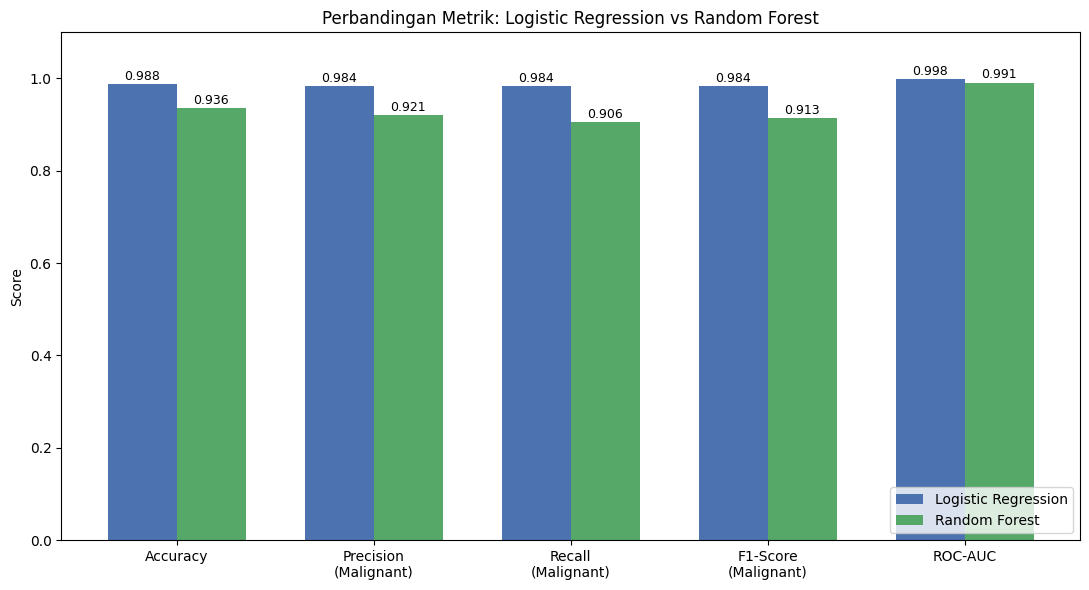

In [40]:
# Data untuk bar chart
metrics = [
    "Accuracy",
    "Precision\n(Malignant)",
    "Recall\n(Malignant)",
    "F1-Score\n(Malignant)",
    "ROC-AUC"
]

lr_scores = [
    accuracy_lr,
    precision_lr,
    recall_lr,
    f1_lr,
    auc_lr
]

rf_scores = [
    accuracy_rf,
    precision_rf,
    recall_rf,
    f1_rf,
    auc_rf
]

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

bars1 = ax.bar(
    x - width/2,
    lr_scores,
    width,
    label="Logistic Regression",
    color="#4C72B0"
)

bars2 = ax.bar(
    x + width/2,
    rf_scores,
    width,
    label="Random Forest",
    color="#55A868"
)

ax.set_ylabel("Score")

ax.set_title(
    "Perbandingan Metrik: Logistic Regression vs Random Forest"
)

ax.set_xticks(x)
ax.set_xticklabels(metrics)

ax.legend(loc="lower right")

ax.set_ylim(0, 1.10)

# Menampilkan nilai di atas setiap batang
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()

        ax.annotate(
            f"{height:.3f}",
            xy=(
                bar.get_x() + bar.get_width()/2,
                height
            ),
            xytext=(0, 3),
            textcoords="offset points",
            ha="center",
            fontsize=9
        )
        import os
os.makedirs("results", exist_ok=True)

plt.tight_layout()
plt.savefig("results/evaluation_results.png", dpi=300, bbox_inches="tight")
plt.show()


# **Step 8: Confusion Matrix**

Confusion Matrix digunakan untuk mengetahui jumlah prediksi benar dan salah dari masing-masing algoritma.

Pada tahap ini, kita akan menampilkan dua Confusion Matrix sekaligus agar hasil kedua algoritma lebih mudah dibandingkan.
Confusion Matrix memiliki empat komponen utama:
| Komponen | Keterangan |
|:--|:--|
| True Positive (TP) | Sampel positif yang diprediksi positif |
| True Negative (TN) | Sampel negatif yang diprediksi negatif |
| False Positive (FP) | Sampel negatif yang diprediksi positif |
| False Negative (FN) | Sampel positif yang diprediksi negatif |

Pada dataset ini, kelas positif secara default adalah kelas 1 (Benign), sedangkan kelas negatif adalah kelas 0 (Malignant).

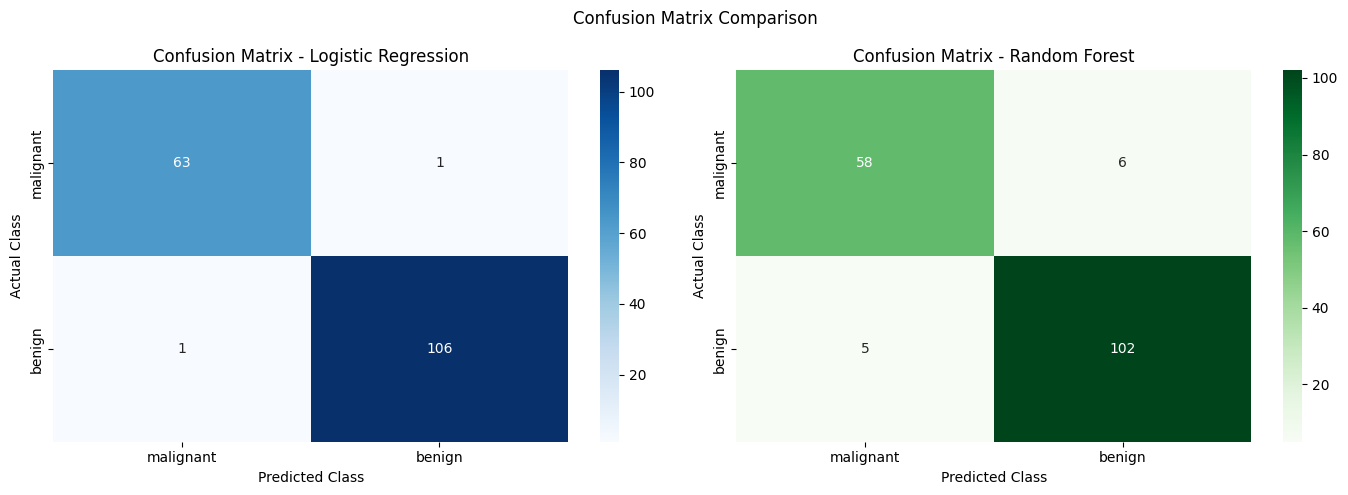

In [41]:
# Menghitung confusion matrix Logistic Regression
cm_lr = confusion_matrix(y_test, y_pred_lr)

# Menghitung confusion matrix Random Forest
cm_rf = confusion_matrix(y_test, y_pred_rf)

# Membuat visualisasi confusion matrix
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion Matrix Logistic Regression
sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=data.target_names,
    yticklabels=data.target_names,
    ax=axes[0]
)

axes[0].set_title("Confusion Matrix - Logistic Regression")
axes[0].set_xlabel("Predicted Class")
axes[0].set_ylabel("Actual Class")


# Confusion Matrix Random Forest
sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=data.target_names,
    yticklabels=data.target_names,
    ax=axes[1]
)

axes[1].set_title("Confusion Matrix - Random Forest")
axes[1].set_xlabel("Predicted Class")
axes[1].set_ylabel("Actual Class")

plt.suptitle("Confusion Matrix Comparison")
import os
os.makedirs("results", exist_ok=True)

plt.tight_layout()
plt.savefig("results/confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

Interpretasi:

- Diagonal utama menunjukkan jumlah prediksi yang benar.
- Sel di luar diagonal menunjukkan jumlah kesalahan prediksi.

Dalam konteks klasifikasi kanker, False Negative untuk kelas malignant berarti tumor ganas salah diprediksi sebagai jinak. Kesalahan ini sangat penting untuk diperhatikan karena dapat menyebabkan kondisi berbahaya jika model digunakan dalam konteks klinis.

# **Step 9: Predict a New Sample**


Tahap terakhir adalah mencoba menggunakan kedua model yang telah dilatih untuk memprediksi satu sampel baru.

Sebagai contoh, kita mengambil satu sampel dari data testing.

In [31]:
# Mengambil satu sampel dari data testing
sample = X_test.iloc[[0]]

# Menampilkan fitur sampel
print("Input Sample:")
print(sample)

# Melakukan prediksi Logistic Regression
prediction_lr = model_lr.predict(sample)[0]

# Mengambil probabilitas Logistic Regression
probability_lr = model_lr.predict_proba(sample)[0]

# Melakukan prediksi Random Forest
prediction_rf = model_rf.predict(sample)[0]

# Mengambil probabilitas Random Forest
probability_rf = model_rf.predict_proba(sample)[0]

# Mengubah label numerik menjadi nama kelas
result_lr = data.target_names[prediction_lr]
result_rf = data.target_names[prediction_rf]

# Menampilkan hasil prediksi Logistic Regression
print("\nLogistic Regression Prediction:", result_lr)

print("\nLogistic Regression Prediction Probability:")

for class_name, prob in zip(data.target_names, probability_lr):
    print(class_name, ":", round(prob * 100, 2), "%")

# Menampilkan hasil prediksi Random Forest
print("\nRandom Forest Prediction:", result_rf)

print("\nRandom Forest Prediction Probability:")

for class_name, prob in zip(data.target_names, probability_rf):
    print(class_name, ":", round(prob * 100, 2), "%")

Input Sample:
    mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
14        13.73         22.61            93.6      578.3           0.1131   

    mean compactness  mean concavity  mean concave points  mean symmetry  \
14            0.2293          0.2128              0.08025         0.2069   

    mean fractal dimension  ...  worst radius  worst texture  worst perimeter  \
14                 0.07682  ...         15.03          32.01            108.8   

    worst area  worst smoothness  worst compactness  worst concavity  \
14       697.7            0.1651             0.7725           0.6943   

    worst concave points  worst symmetry  worst fractal dimension  
14                0.2208          0.3596                   0.1431  

[1 rows x 30 columns]

Logistic Regression Prediction: malignant

Logistic Regression Prediction Probability:
malignant : 96.79 %
benign : 3.21 %

Random Forest Prediction: malignant

Random Forest Prediction Probability:
malignant :

Penjelasan:

1. X_test.iloc[[0]] mengambil satu sampel dari data testing.
2. predict() menghasilkan kategori hasil klasifikasi.
3. predict_proba() menghasilkan probabilitas prediksi untuk masing-masing kelas.
4. data.target_names mengubah label numerik menjadi nama kategori.

Catatan: Model ini digunakan hanya untuk pembelajaran dan demonstrasi Machine Learning. Hasil prediksi tidak boleh digunakan sebagai pengganti diagnosis medis profesional.


**Hasil Perbandingan & Kesimpulan Eksperimen:**

Berdasarkan hasil pengujian pada pembagian data 70% training (398 sampel) dan 30% testing (171 sampel), **Logistic Regression memberikan performa klasifikasi yang lebih baik dibandingkan Random Forest Classifier** di seluruh metrik evaluasi:

- **Accuracy:** Logistic Regression mencapai **98,83%** (hanya 2 salah prediksi dari 171 sampel), lebih tinggi dibandingkan Random Forest sebesar **93,57%** (11 salah prediksi).
- **Precision (Malignant):** Logistic Regression **98,44%** vs Random Forest **92,06%**.
- **Recall (Malignant):** Logistic Regression **98,44%** (hanya 1 kasus tumor ganas yang terlewat / False Negative) vs Random Forest **90,62%** (6 kasus tumor ganas terlewat / False Negative).
- **F1-Score (Malignant):** Logistic Regression **98,44%** vs Random Forest **91,34%**.
- **ROC-AUC:** Logistic Regression **0,9981** vs Random Forest **0,9913**.

Dengan demikian, **Logistic Regression** lebih direkomendasikan pada dataset ini karena memiliki tingkat kesalahan *False Negative* yang jauh lebih rendah pada deteksi tumor ganas (*malignant*).

**Analisis Perbandingan Kedua Algoritma**

Analisis dilakukan berdasarkan hasil tabel evaluasi, grafik perbandingan, dan Confusion Matrix yang telah diperoleh.

Dalam menentukan algoritma yang lebih baik, beberapa hal yang perlu diperhatikan adalah:
- Accuracy menunjukkan tingkat ketepatan prediksi secara keseluruhan.
- Precision Malignant menunjukkan ketepatan model ketika memprediksi tumor ganas.
- Recall Malignant menunjukkan kemampuan model dalam mendeteksi seluruh sampel tumor ganas.
- F1-Score Malignant menunjukkan keseimbangan antara precision dan recall.
- ROC-AUC menunjukkan kemampuan model dalam membedakan tumor ganas dan jinak.
Khusus dalam klasifikasi kanker, nilai Recall pada kelas Malignant perlu mendapatkan perhatian karena berkaitan dengan kemampuan model mengenali tumor ganas.

**Mengapa Evaluasi Model Tidak Cukup Hanya Menggunakan Accuracy?**

  Dalam konteks klasifikasi kanker, accuracy saja tidak cukup karena metrik tersebut hanya menunjukkan persentase keseluruhan prediksi yang benar tanpa memperhatikan jenis kesalahan klasifikasi.

Model dapat memiliki nilai accuracy tinggi, tetapi masih mengalami kesalahan dalam mengidentifikasi tumor ganas yang justru diklasifikasikan sebagai tumor jinak. Kesalahan tersebut disebut False Negative dan dapat berdampak serius apabila hasil klasifikasi digunakan sebagai informasi pendukung pemeriksaan kesehatan.

Oleh karena itu, diperlukan metrik tambahan seperti precision, recall, dan F1-score. Recall digunakan untuk mengetahui kemampuan model mendeteksi tumor ganas, precision menunjukkan ketepatan prediksi kelas, sedangkan F1-score menggambarkan keseimbangan antara precision dan recall. ROC-AUC juga digunakan untuk mengetahui kemampuan model dalam membedakan kedua kategori tumor.

Dengan demikian, evaluasi menggunakan beberapa metrik memberikan gambaran performa model yang lebih menyeluruh dibandingkan hanya menggunakan accuracy.